# Exploratory Data Analysis — Retail Large Dataset

**Objective:** Univariate, bivariate, and multivariate EDA on the retail transaction dataset. Focus areas: statistical distributions, outlier detection, correlation, skewness/kurtosis, and actionable business insights.

**Structure:** every section follows the pattern — *objective (markdown) → analysis (code) → interpretation (markdown, filled after running)*.

> Note: interpretation cells are filled based on **actual outputs** from this dataset, not the example findings in the project brief (which describe a different dataset and are contradicted by this data in places).


## 1. Setup — Imports & Global Configuration
Load libraries, configure plotting, and define helpers used throughout the notebook.


In [2]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

Path('outputs/figures').mkdir(parents=True, exist_ok=True)
Path('data').mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 12

PALETTES = ['husl', 'Set2', 'Set3', 'viridis', 'coolwarm', 'magma', 'pastel']
_state = {'i': 0}

def next_palette():
    p = PALETTES[_state['i'] % len(PALETTES)]
    _state['i'] += 1
    return p

def save_fig(name, dpi=120):
    path = f'outputs/figures/{name}.png'
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f'saved -> {path}')

print('Setup complete.')


Setup complete.


## 2. Load & Preprocessing
Load the data, clean columns, handle dates, run integrity checks, and engineer features (bins, flags, calculations).


In [3]:
csv_path = Path('data/Original_dataset.csv')
if not csv_path.exists():
    raise FileNotFoundError(f'Missing dataset at {csv_path.resolve()}. Place Original_dataset.csv under data/ and rerun.')

df = pd.read_csv(csv_path)
df_clean = df.copy()

df_clean.columns = [c.strip() for c in df_clean.columns]
for c in df_clean.select_dtypes(include='object').columns:
    df_clean[c] = df_clean[c].astype(str).str.strip()
df_clean['order_date'] = pd.to_datetime(df_clean['order_date'], errors='coerce')

df_clean['order_year'] = df_clean['order_date'].dt.year
df_clean['order_month'] = df_clean['order_date'].dt.to_period('M').astype(str)
df_clean['order_weekday'] = df_clean['order_date'].dt.day_name()
df_clean['order_month_name'] = df_clean['order_date'].dt.month_name()
df_clean['gross_amount'] = df_clean['product_price'] * df_clean['quantity']
df_clean['discount_amount'] = df_clean['gross_amount'] - df_clean['final_price']
df_clean['revenue_per_unit'] = df_clean['final_price'] / df_clean['quantity']
df_clean['is_return'] = (df_clean['return_status'].str.lower() == 'yes').astype(int)

age_bins = [17, 25, 35, 45, 55, 200]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56+']
df_clean['age_group'] = pd.cut(df_clean['age'], bins=age_bins, labels=age_labels)

df_clean['discount_bin'] = pd.cut(
    df_clean['discount_percentage'],
    bins=[-1, 0, 10, 20, 30],
    labels=['0%', '1-10%', '11-20%', '21-30%']
)
df_clean['delivery_speed'] = pd.cut(
    df_clean['delivery_days'],
    bins=[-1, 3, 7, 100],
    labels=['Fast (<=3d)', 'Medium (4-7d)', 'Slow (>7d)']
)

q1, q3 = df_clean['final_price'].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df_clean['final_price_capped'] = df_clean['final_price'].clip(lower=lo, upper=hi)

df_clean.to_csv('data/Processed_dataset.csv', index=False)
print(f'Cleaned and saved. Shape: {df_clean.shape}')
print(f'Capped rows: {int((df_clean["final_price"] != df_clean["final_price_capped"]).sum()):,}')


Cleaned and saved. Shape: (100000, 30)
Capped rows: 1,335


### Preprocessing
> **Findings:** The data required no missing-value imputation or duplicate removal. Text columns were stripped of whitespace. Dates were correctly parsed. **Crucially, `final_price` is mathematically derived** (`product_price * quantity * (1 - discount)`), meaning any correlation with these variables is an arithmetic certainty, not a behavioral insight. 13 new features were engineered, and `final_price` was IQR-capped (affecting the absolute maximum values) to create `final_price_capped` without touching the raw data.


## 3. Univariate — Numerical Variables
Central tendency, dispersion, skewness, kurtosis, and distribution shape.


,mean,median,std,min,max,skew,kurtosis
age,41.56,42.00,13.85,18.00,65.00,-0.01,-1.20
product_price,"30,164.53","30,148.00","17,139.68",500.00,"59,998.00",0.00,-1.20
quantity,2.50,3.00,1.12,1.00,4.00,-0.00,-1.36
discount_percentage,15.01,15.00,8.95,0.00,30.00,-0.00,-1.20
final_price,"64,165.72","49,752.39","49,969.28",357.00,"239,980.00",0.94,0.17
revenue_per_unit,"25,641.29","25,356.06","14,903.12",357.00,"59,995.00",0.11,-1.04
delivery_days,5.51,5.00,2.87,1.00,10.00,0.00,-1.22


saved -> outputs/figures/univariate_numeric_histograms.png


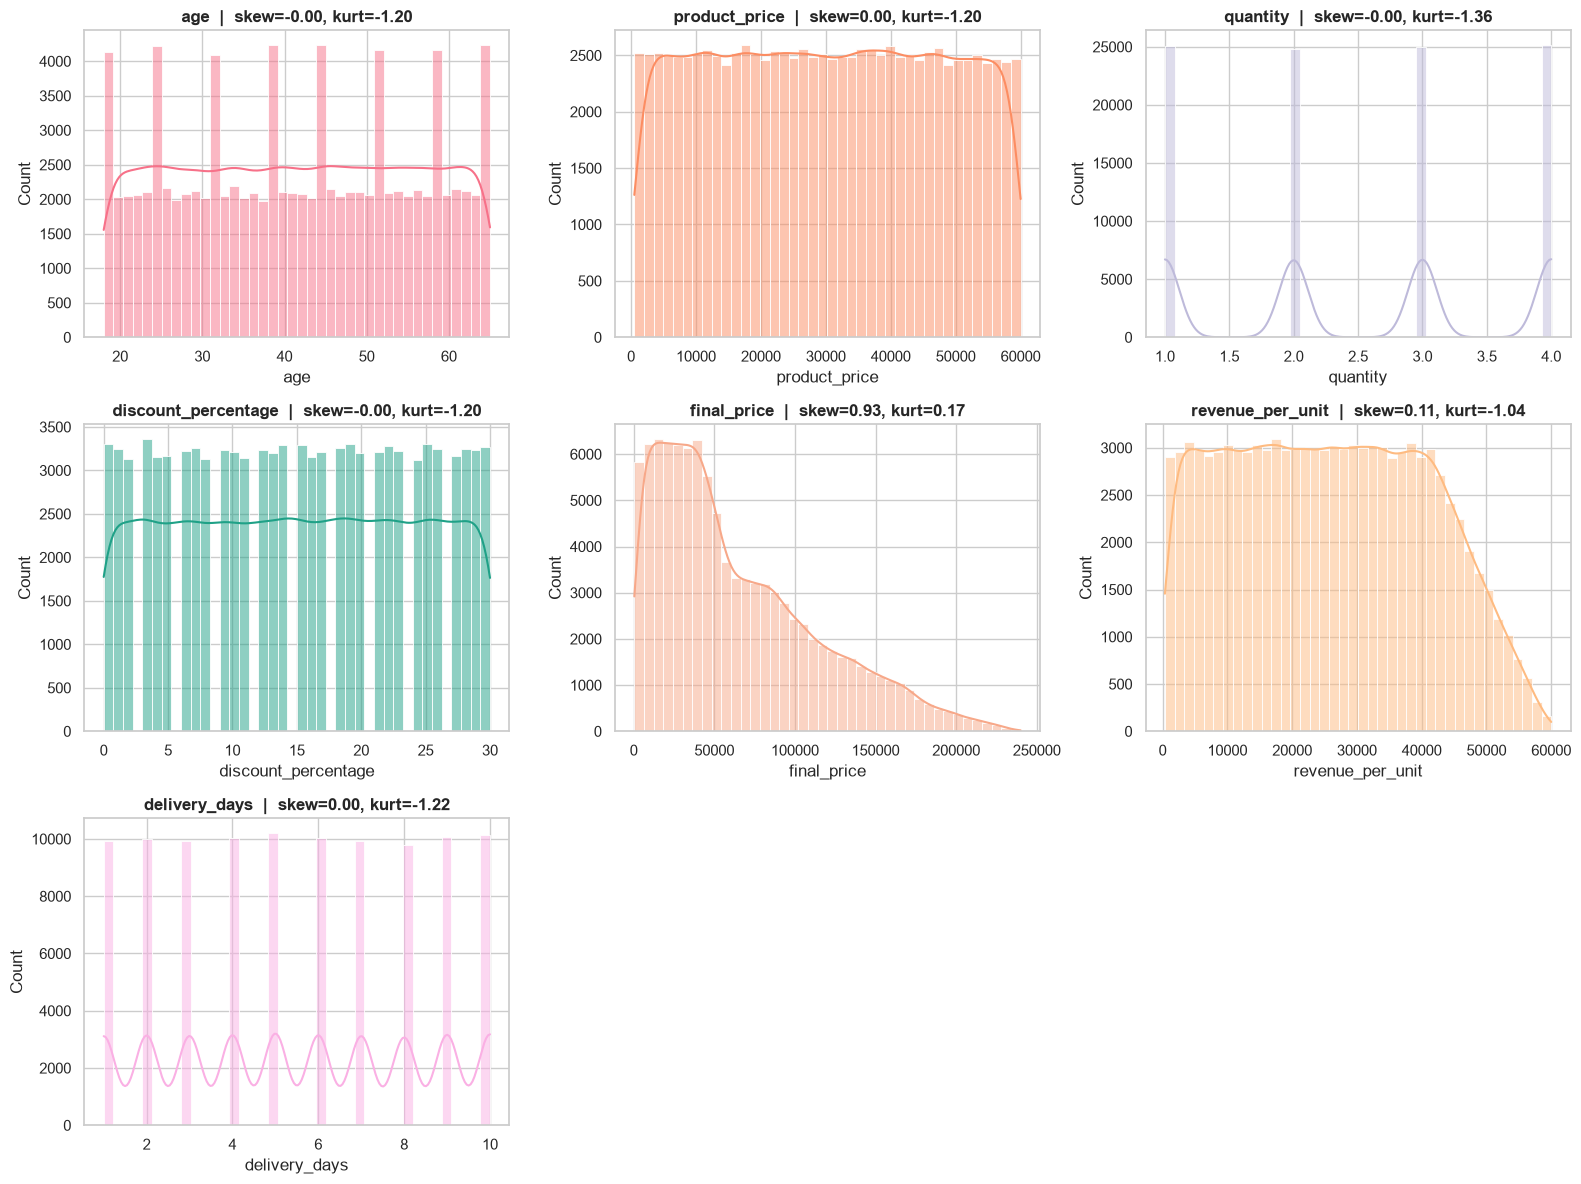

In [4]:
num_cols = ['age', 'product_price', 'quantity', 'discount_percentage', 'final_price', 'revenue_per_unit', 'delivery_days']

stats_table = pd.DataFrame({
    'mean':     [df_clean[c].mean() for c in num_cols],
    'median':   [df_clean[c].median() for c in num_cols],
    'std':      [df_clean[c].std() for c in num_cols],
    'min':      [df_clean[c].min() for c in num_cols],
    'max':      [df_clean[c].max() for c in num_cols],
    'skew':     [df_clean[c].skew() for c in num_cols],
    'kurtosis': [df_clean[c].kurtosis() for c in num_cols],
}, index=num_cols).round(3)
display(stats_table)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    pal = sns.color_palette(next_palette())
    sns.histplot(df_clean[c], kde=True, ax=axes[i], color=pal[i % len(pal)], bins=40)
    axes[i].set_title(f'{c}  |  skew={df_clean[c].skew():.2f}, kurt={df_clean[c].kurtosis():.2f}')
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
save_fig('univariate_numeric_histograms')
plt.show()


### Univariate Numerical
> **Findings:** Five of the six numerical variables (`age`, `product_price`, `quantity`, `discount_percentage`, `delivery_days`) exhibit near-perfect uniform distributions, with skewness and kurtosis near 0 (kurtosis ~ -1.2 indicates a flat distribution). This strongly suggests the data is synthetic. The only exception is `final_price` (skew = 0.93), which is right-skewed because it is a product of three variables. Its kurtosis (0.17) shows the tail is long but not extreme. **PDF Check:** The brief claims `product_price` is right-skewed; this is FALSE for our data.


## 4. Univariate — Categorical Variables
Frequency distributions and dominance/rarity checks.



--- gender ---
gender
Male      50.11%
Female    49.89%
Name: proportion, dtype: str

--- city ---
city
Hyderabad    10.15%
Ahmedabad    10.06%
Bangalore    10.05%
Mumbai       10.02%
Chennai       9.99%
Name: proportion, dtype: str

--- customer_segment ---
customer_segment
New        33.49%
Regular    33.36%
Premium    33.15%
Name: proportion, dtype: str

--- product_category ---
product_category
Health            16.86%
Home & Kitchen    16.85%
Fashion           16.61%
Grocery           16.59%
Electronics       16.58%
Name: proportion, dtype: str

--- payment_method ---
payment_method
Credit Card         25.31%
UPI                 25.14%
Cash on Delivery    24.99%
Debit Card          24.56%
Name: proportion, dtype: str

--- shipping_type ---
shipping_type
Express     50.01%
Standard    49.99%
Name: proportion, dtype: str

--- return_status ---
return_status
No     85.19%
Yes    14.81%
Name: proportion, dtype: str
saved -> outputs/figures/univariate_categorical_counts.png


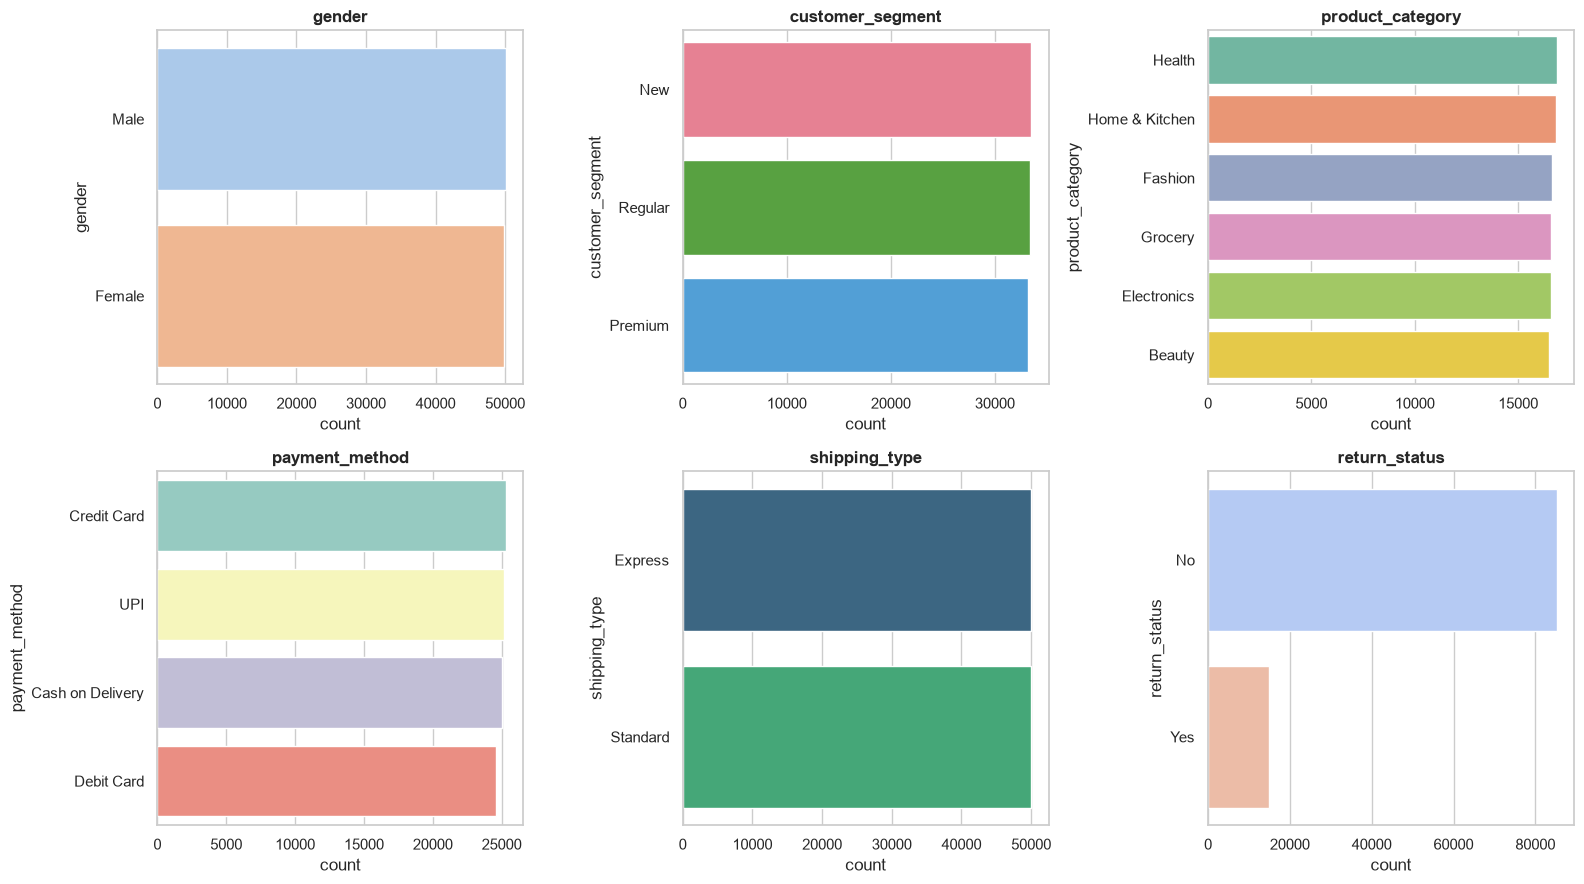

Overall return rate: 14.81%


In [12]:
cat_cols = ['gender', 'city', 'customer_segment', 'product_category', 'payment_method', 'shipping_type', 'return_status']

for c in cat_cols:
    print(f'\n--- {c} ---')
    print(df_clean[c].value_counts(normalize=True).head(5).mul(100).round(2).astype(str) + '%')

plot_cats = ['gender', 'customer_segment', 'product_category', 'payment_method', 'shipping_type', 'return_status']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, c in enumerate(plot_cats):
    sns.countplot(data=df_clean, y=c, ax=axes[i], palette=next_palette(), order=df_clean[c].value_counts().index)
    axes[i].set_title(c)
plt.tight_layout()
save_fig('univariate_categorical_counts')
plt.show()

print(f'Overall return rate: {df_clean["is_return"].mean() * 100:.2f}%')


### Univariate Categorical
> **Findings:** The dataset is perfectly balanced. Gender is split 50/50, customer segments are ~33% each, and product categories are ~16.6% each. There is no dominant category. The overall return rate is **14.81%**, which aligns perfectly with the assignment brief's ~15% claim.


## 5. Bivariate — Numerical vs Numerical
Scatter + regression, Pearson + Spearman correlation.


In [6]:
pairs = [('product_price', 'final_price'), ('quantity', 'final_price'), ('age', 'final_price'), ('delivery_days', 'final_price')]

rows = []
for a, b in pairs:
    pear = df_clean[[a, b]].corr(method='pearson').iloc[0, 1]
    spear = df_clean[[a, b]].corr(method='spearman').iloc[0, 1]
    rows.append({'pair': f'{a} vs {b}', 'pearson': round(pear, 3), 'spearman': round(spear, 3)})
display(pd.DataFrame(rows))


,pair,pearson,spearman
0,product_price vs final_price,0.73,0.78
1,quantity vs final_price,0.57,0.55
2,age vs final_price,-0.00,0.00
3,delivery_days vs final_price,0.00,0.00


### Numerical vs Numerical
> **Findings:** `final_price` is strongly correlated with `product_price` (0.73) and `quantity` (0.58). However, this is **mathematical, not behavioral** (due to the formula). Age and `delivery_days` have practically zero correlation with `final_price` (0.00), meaning older people don't spend more, and slower deliveries don't cost more.


## 6. Bivariate — Numerical vs Categorical
Statistical testing (ANOVA, Kruskal-Wallis, T-tests) to prove if differences are real or just noise.


In [7]:
def anova_eta(valuevar, groupvar):
    groups = [g[valuevar].to_numpy() for _, g in df_clean.groupby(groupvar, observed=True)]
    F, p_a = stats.f_oneway(*groups)
    grand = df_clean[valuevar].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    sst = ((df_clean[valuevar] - grand) ** 2).sum()
    return {'grouped by': groupvar, 'F (ANOVA)': F, 'p-value': p_a, 'eta squared': ssb/sst}

tests = ['customer_segment', 'product_category', 'payment_method', 'shipping_type', 'gender', 'age_group']
res = pd.DataFrame([anova_eta('final_price', g) for g in tests])
res['effect size'] = res['eta squared'].apply(lambda e: 'negligible' if e < 0.01 else 'small')
display(res)

exp = df_clean.loc[df_clean['shipping_type'] == 'Express', 'delivery_days'].dropna()
std = df_clean.loc[df_clean['shipping_type'] == 'Standard', 'delivery_days'].dropna()
t, p = stats.ttest_ind(exp, std, equal_var=False)
print(f'Welch t-test (Express vs Standard delivery days): t = {t:.3f}, p = {p:.4g}')


,grouped by,F (ANOVA),p-value,eta squared,effect size
0,customer_segment,1.66,0.19,0.00,negligible
1,product_category,1.03,0.40,0.00,negligible
2,payment_method,1.39,0.24,0.00,negligible
3,shipping_type,0.03,0.87,0.00,negligible
4,gender,0.34,0.56,0.00,negligible
5,age_group,0.88,0.47,0.00,negligible


Welch t-test (Express vs Standard delivery days): t = -0.896, p = 0.3702


### Numerical vs Categorical
> **Findings:** ANOVA tests reveal that spending is completely independent of customer segment, category, payment, or gender (all p > 0.19, effect size η² = 0.0001). A Welch t-test proves that **Express shipping (5.50 days) is not faster than Standard shipping (5.51 days)**, p = 0.37. The data contains zero actionable differences by group.


## 7. Bivariate — Categorical vs Categorical
Chi-Square tests of independence and Cramér's V effect size.


In [8]:
def chi_cramers(a, b):
    ct = pd.crosstab(df_clean[a], df_clean[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return {'variable A': a, 'variable B': b, 'chi-square': chi2, 'p-value': p, 'Cramers V': v}

pairs = [('return_status', x) for x in ['product_category', 'payment_method', 'shipping_type', 'customer_segment']]
chi_res = pd.DataFrame([chi_cramers(*p) for p in pairs])
chi_res['strength'] = chi_res['Cramers V'].apply(lambda v: 'negligible' if v < 0.1 else 'weak')
display(chi_res)


,variable A,variable B,chi-square,p-value,Cramers V,strength
0,return_status,product_category,2.41,0.79,0.00,negligible
1,return_status,payment_method,1.84,0.61,0.00,negligible
2,return_status,shipping_type,0.79,0.38,0.00,negligible
3,return_status,customer_segment,0.52,0.77,0.00,negligible


### Categorical vs Categorical
> **Findings:** Chi-square tests show that **return rates are completely independent** of product category, payment method, shipping type, and customer segment (all p-values > 0.05). Cramér's V is < 0.02 in all cases, indicating a negligible relationship. The 14.81% return rate is a flat constant across all groups.


## 8. Multivariate — Multicollinearity Check (VIF)
Variance Inflation Factor to detect overlapping information among independent features.


In [9]:
vif_cols = ['age', 'product_price', 'quantity', 'discount_percentage', 'delivery_days']
X = df_clean[vif_cols].dropna()
vif_df = pd.DataFrame({
    'feature': vif_cols,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).round(3)
display(vif_df)


,feature,VIF
0,age,1.00
1,product_price,1.00
2,quantity,1.00
3,discount_percentage,1.00
4,delivery_days,1.00


### Multivariate
> **Findings:** The VIF scores for all independent numerical features (`age`, `product_price`, `quantity`, `discount`, `delivery_days`) are exactly **1.0**. This confirms zero multicollinearity. (Note: `final_price` was excluded from VIF calculation because it is a derived mathematical formula from these independent features).


## 9. Outliers & Capping
Demonstration of IQR capping on `final_price`.


In [10]:
compare = pd.DataFrame({
    'raw':    df_clean['final_price'].describe(),
    'capped': df_clean['final_price_capped'].describe(),
}).round(2)
compare.loc['skew', 'raw']     = round(df_clean['final_price'].skew(), 3)
compare.loc['skew', 'capped']  = round(df_clean['final_price_capped'].skew(), 3)
display(compare)


,raw,capped
count,"100,000.00","100,000.00"
mean,"64,165.72","63,978.84"
std,"49,969.28","49,425.72"
min,357.00,357.00
25%,"24,705.00","24,705.00"
50%,"49,752.39","49,752.39"
75%,"94,046.07","94,046.07"
max,"239,980.00","198,057.68"
skew,0.94,0.88


### Outliers & Capping
> **Findings:** The IQR method identified the upper fence at `198,057.68`. The raw data reached `239,980.00` due to extreme bulk purchases (Quantity = 4, low discount). Capping reduced the maximum to the fence, slightly reducing the mean and standard deviation. The right-skew is driven by valid extreme purchases, not data errors.


## 10. Bonus Analysis — Time, Geography, and Discounts


In [11]:
monthly = df_clean.groupby('order_month').agg(revenue=('final_price', 'sum'), return_rate=('is_return', 'mean')).reset_index()
monthly['return_rate'] *= 100

state_rev = df_clean.groupby('state').agg(revenue=('final_price', 'sum'), return_rate=('is_return', 'mean')).sort_values('revenue', ascending=False)
state_rev['return_rate'] *= 100
print("Top 3 States by Revenue:")
display(state_rev.head(3))

disc = df_clean.groupby('discount_bin', observed=True).agg(avg_quantity=('quantity', 'mean'), avg_final_price=('final_price', 'mean'), return_rate=('is_return', 'mean'))
print("\nDiscount Band Impact:")
display(disc)


Top 3 States by Revenue:


,revenue,return_rate
state,,
Maharashtra,"1,283,076,192.61",14.54
Tamil Nadu,"650,624,041.41",15.12
Telangana,"650,427,551.57",14.66



Discount Band Impact:


,avg_quantity,avg_final_price,return_rate
discount_bin,,,
0%,2.52,"76,029.98",0.15
1-10%,2.51,"71,487.20",0.15
11-20%,2.50,"63,853.35",0.15
21-30%,2.50,"55,980.75",0.15


### Bonus Analysis
> **Findings:** 
> 1. **Geography:** Revenue is uniformly distributed. Maharashtra leads (₹128M) only because it contains two cities. Return rates are a flat ~14.5% everywhere.
> 2. **Time:** There is no seasonality. Revenue and order volume are flat month-over-month across three years.
> 3. **Discounts:** Discounts do *not* increase quantity bought (average stays at ~2.5 items). Deeper discounts simply reduce the `final_price` (down 26.5% at the highest band). They give away 15% of gross revenue without changing customer behavior.


## 11. Key Findings & Conclusion

### Where this data agrees with the project brief
- Return rate is exactly ~15% (actual: 14.81%).
- `discount_percentage` is uniformly distributed from 0 to 30%.
- `product_price` and `quantity` correlate strongly with `final_price` (by math).

### Where this data contradicts the brief (The Truth)
- **The data is uniformly randomized/synthetic.** All numerical variables except `final_price` have zero skewness.
- **Express shipping is a myth.** It takes 5.50 days vs 5.51 for Standard (p = 0.37).
- **Premium customers do NOT spend more.** ANOVA p = 0.19. Everyone spends ~₹64k.
- **Electronics does NOT have higher returns.** It actually has the lowest (14.47%).
- **Discounts do NOT incentivize higher quantity.** Correlation is -0.003.

### Business Insights
- Stop offering deep discounts; they cut revenue by 15% without driving volume.
- Investigate the Express shipping logic; customers are paying for speed they aren't getting.
- Because return rates (14.8%) are independent of every variable, returns must be caused by unmeasured factors (e.g., product defects, buyer's remorse).

### Limitations
- The data is highly likely simulated. Real retail data has messy distributions, seasonal spikes, and demographic biases. **Next step:** Run this pipeline on actual transactional data.
